In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import nanonets
import matplotlib.cm as cm
import matplotlib.colors as mcolors

from nanonets.utils.signals import extract_harmonic_features, get_phase_lag, compute_thd
from scipy.interpolate import UnivariateSpline

plt.style.use(["science","bright","grid"])

In [ ]:
N_PERIODS       = 100
SAMPLE_P_PERIOD = 40
N_EQ_PERIODS    = 40
SELF_CAP        = 0.0

# Fix Parameter
FREQ_MHZ    = 500.0
AMP_MULT    = 3
TOPO        = {"Nx": 1, "Ny": 1, "electrode_type" : ['constant','constant']}
sim         = nanonets.Simulation(TOPO, SELF_CAP)
AMPLITUDE   = AMP_MULT * sim.electrostatic.get_charging_energies()[0]*1e-3
R_MAX       = 25.0
R_MIN       = 5.0 

TAU_LIST            = [0.1e-9, 0.2e-9, 1.0e-9, 2.0e-9, 6.0e-9, 20.0e-9, 100.0e-9]
TARGET_CURRENT_LIST = [1.0, 5.0, 10.0, 20.0, 40.0, 80.0, 150.0, 300.0, 600.0, 1200.0]

In [31]:
TAU_LIST            = [0.1e-9, 0.2e-9, 1.0e-9, 2.0e-9, 6.0e-9, 20.0e-9, 100.0e-9]
TARGET_CURRENT_LIST = [1.0, 5.0, 10.0, 20.0, 40.0, 80.0, 150.0, 300.0, 600.0, 1200.0]
data_raw            = {i_target : {tau*1e9 : pd.read_csv(f"../../data/raw/dynamic_resistances/set_I0_tau_0/set_tau{tau*1e9:.3f}_i_target{i_target:.2f}.csv").iloc[N_EQ_PERIODS*SAMPLE_P_PERIOD:,:]
                                for tau in TAU_LIST} for i_target in TARGET_CURRENT_LIST}
resistance_raw      = {i_target : {tau*1e9 : pd.read_parquet(f"../../data/raw/dynamic_resistances/set_I0_tau_0/resistances_set_tau{tau*1e9:.3f}_i_target{i_target:.2f}.parquet").iloc[N_EQ_PERIODS*SAMPLE_P_PERIOD:,:].mean(axis=1).values
                                for tau in TAU_LIST} for i_target in TARGET_CURRENT_LIST}

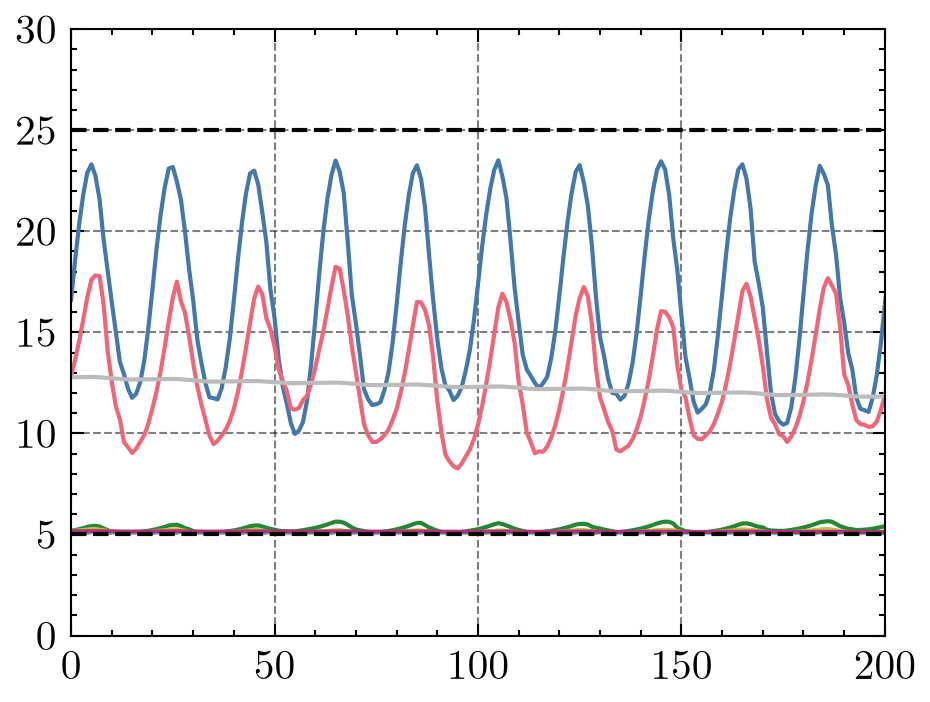

In [87]:
fig = plt.figure(dpi=300)
ax  = fig.add_subplot()

for tau in TAU_LIST:
    _ = ax.plot(resistance_raw[150][tau*1e9])

ax.set_xlim(0,200)
ax.axhline(R_MIN, color='black', ls='--')
ax.axhline(R_MAX, color='black', ls='--')
_ = ax.set_ylim(0, 30)

(0.0, 500.0)

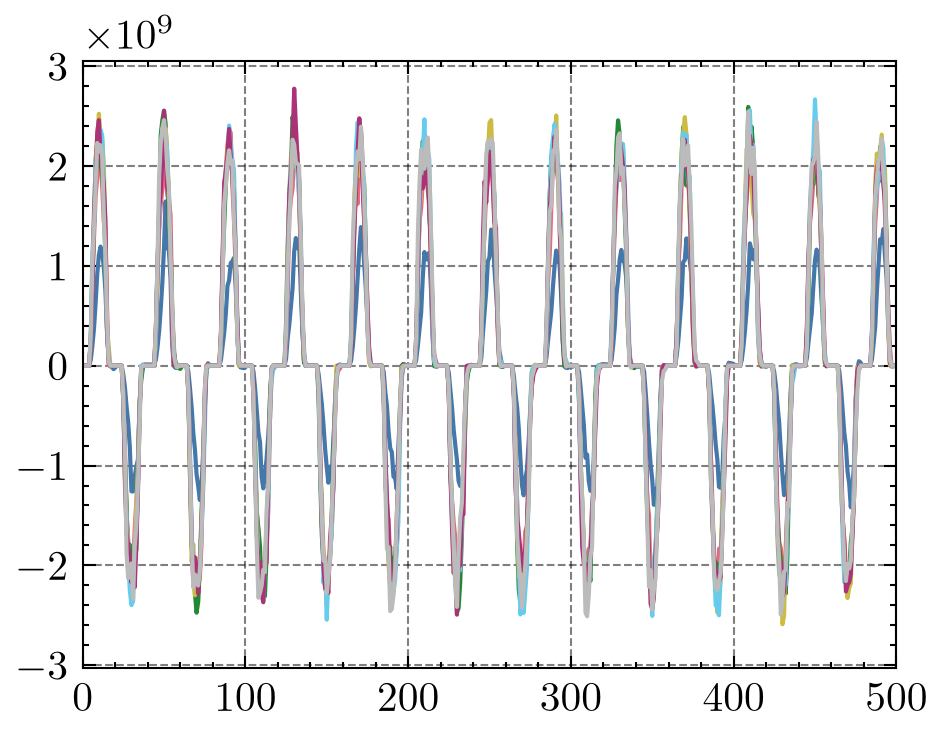

In [86]:
fig = plt.figure(dpi=300)
ax  = fig.add_subplot()

for tau in TAU_LIST:
    _ = ax.plot(data_raw[20.0][tau*1e9]['Observable'].values)

ax.set_xlim(0,500)